# The graphs in `agents/`

Renders the compiled LangGraph graphs declared in `src/agentic_review/agents/` (ADR-0009, ADR-0010). There are two:

| Graph | Builder | Shape |
|---|---|---|
| Pipeline (main agent) | `pipeline_agent.build_pipeline_graph` | acyclic, one node per CF phase |
| Review reporting agent (CF-6) | `review_reporting_agent.build_review_graph` | the only place a cycle may occur (repair edge) |

`review_port.py` declares no graph of its own: `LangGraphReviewPort` wraps the review graph.

No model is called: the review graph is built with a stand-in model that is never invoked.

## Setup

In [7]:
from IPython.display import Image, Markdown, display
from langchain_core.runnables import RunnableLambda

from agentic_review.agents.pipeline_agent import build_pipeline_graph
from agentic_review.agents.review_reporting_agent import build_review_graph


def show(compiled, title):
    """Render as PNG (mermaid.ink, needs network); fall back to the Mermaid source."""
    graph = compiled.get_graph()
    print(title, "| nodes:", list(graph.nodes), "| edges:", len(graph.edges))
    try:
        display(Image(graph.draw_mermaid_png()))
    except Exception as error:
        print(f"PNG render unavailable ({type(error).__name__}); Mermaid source below - paste into mermaid.live")
        print(graph.draw_mermaid())


## 1 · Pipeline graph (main agent)

Fixed order, acyclic. `preflight` may route straight to the end.

pipeline | nodes: ['__start__', 'preflight', 'resolve_change_set', 'parse_and_context', 'execute_checks', 'load_patterns', 'assemble_context', 'review_agent', 'build_report', '__end__'] | edges: 10


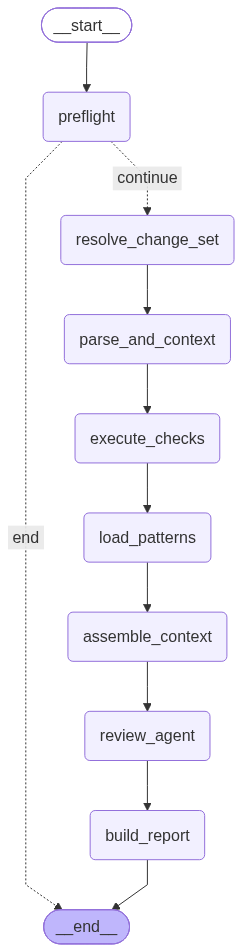

In [8]:
pipeline = build_pipeline_graph()
show(pipeline, 'pipeline')

## 2 · Review reporting agent graph (CF-6)

The `decide_repair` → `call_model` edge is the one permitted cycle.

review | nodes: ['__start__', 'call_model', 'validate_calls', 'record_coverage', 'decide_repair', '__end__'] | edges: 7


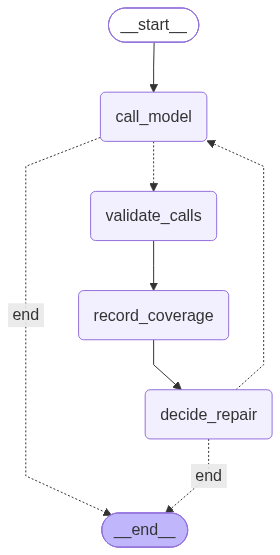

In [9]:
stand_in_model = RunnableLambda(lambda messages: None)  # never invoked; the graph only needs it to build
review = build_review_graph(stand_in_model)
show(review, 'review')

## 3 · Mermaid source

For pasting into docs (the repo's docs use mermaid).

In [12]:
fence = "`" * 3
for name, compiled in [("pipeline", pipeline), ("review", review)]:
    source = compiled.get_graph().draw_mermaid()
    display(Markdown("**" + name + "**" + chr(10)*2 + fence + "mermaid" + chr(10) + source + chr(10) + fence))

**pipeline**

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	preflight(preflight)
	resolve_change_set(resolve_change_set)
	parse_and_context(parse_and_context)
	execute_checks(execute_checks)
	load_patterns(load_patterns)
	assemble_context(assemble_context)
	review_agent(review_agent)
	build_report(build_report)
	__end__([<p>__end__</p>]):::last
	__start__ --> preflight;
	assemble_context --> review_agent;
	execute_checks --> load_patterns;
	load_patterns --> assemble_context;
	parse_and_context --> execute_checks;
	preflight -. &nbsp;end&nbsp; .-> __end__;
	preflight -. &nbsp;continue&nbsp; .-> resolve_change_set;
	resolve_change_set --> parse_and_context;
	review_agent --> build_report;
	build_report --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```

**review**

```mermaid
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	call_model(call_model)
	validate_calls(validate_calls)
	record_coverage(record_coverage)
	decide_repair(decide_repair)
	__end__([<p>__end__</p>]):::last
	__start__ --> call_model;
	call_model -. &nbsp;end&nbsp; .-> __end__;
	call_model -.-> validate_calls;
	decide_repair -. &nbsp;end&nbsp; .-> __end__;
	decide_repair -.-> call_model;
	record_coverage --> decide_repair;
	validate_calls --> record_coverage;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

```